<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/02%20-%20Supervised%20Learning/02b_knn_and_svm.ipynb)

# 02b · 基于距离与边界的模型：k 近邻（kNN）与支持向量机（SVM）

在上一节（`02a`）中，线性回归假设全世界的分子都服从同一个全局加权公式，测试集 RMSE 停在了 `1.64` 左右。但化学家平时预测一个未知分子的性质时，往往用的是另一种非常朴素的直觉——**相似性原理（Similarity Principle）**：

> **“不用写全局方程，直接去已知数据库里找几个跟它结构/极性最像的‘邻居分子’，参考它们的实验值；或者在特征空间里画一条光滑的曲面把不同性质的区域隔开。”**

这一节我们就拆解两类完全基于**特征空间几何距离与边界**的经典算法：**k 近邻（kNN）** 与 **支持向量机（SVM / SVR）**。

### 本节内容
1. kNN 几何原理：在 `(MolLogP, MolWt)` 分子平面亲眼看“找邻居”
2. 为什么不缩放特征会把邻居彻底找歪？（`StandardScaler` 与防泄漏铁律）
3. 邻居数 $k$ 的偏差–方差权衡
4. 支持向量机（SVM）核心原理：最大间隔超平面、软间隔 $C$ 与 **RBF 核技巧**
5. 支持向量回归（SVR）：$\epsilon$-不敏感管道与 AqSolDB 非线性等高线实战

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "02 - Supervised Learning"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


## 0. 环境准备与读取 AqSolDB 数据

In [2]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error, r2_score

RDLogger.DisableLog("rdApp.*")

<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


In [4]:
DATA_FILE = "data/solubility.csv" if os.path.exists("data/solubility.csv") else "../01 - Basics/data/solubility.csv"
df = pd.read_csv(DATA_FILE)
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]
X = df[feature_cols].values
y = df["Solubility"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def evaluate_reg(model, X_tr, y_tr, X_te, y_te, label="Model"):
    model.fit(X_tr, y_tr)
    tr_rmse = root_mean_squared_error(y_tr, model.predict(X_tr))
    te_pred = model.predict(X_te)
    te_rmse = root_mean_squared_error(y_te, te_pred)
    te_r2 = r2_score(y_te, te_pred)
    print(f"{label:26s} | 训练 RMSE = {tr_rmse:.3f} | 测试 RMSE = {te_rmse:.3f} | 测试 R² = {te_r2:.3f}")
    return te_rmse

results = {"Baseline (Mean)": 2.420}
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
results["Ridge Linear"] = evaluate_reg(Ridge(alpha=50.0), X_train_s, y_train, X_test_s, y_test, "Ridge Linear (02a)")

Ridge Linear (02a)         | 训练 RMSE = 1.669 | 测试 RMSE = 1.649 | 测试 R² = 0.535


---
## 1. k 近邻（kNN）几何原理与“不缩放找错邻居”现场直击

### 📘 1.1 零训练公式的“记忆型”算法

**k 近邻（k-Nearest Neighbors, kNN）** 是整个机器学习里原理最直观的模型：
1. **训练阶段（`fit`）**：几乎什么都不算，只是把训练集所有分子 $(X_{\text{train}}, y_{\text{train}})$ 原封不动存进内存；
2. **预测阶段（`predict`）**：给定一个新分子 $\mathbf{x}_{\text{new}}$，计算它与库里每一个已知分子的欧氏距离：
   $$d(\mathbf{x}_{\text{new}}, \mathbf{x}_i) = \sqrt{\sum_{j=1}^p (x_{\text{new}, j} - x_{i, j})^2}$$
   挑出距离最近的 $k$ 个邻居分子，把它们实验 $\log S$ 的**平均值**（分类任务则是多数投票）作为预测结果！

### 🤔 先猜一猜：为什么直接算欧氏距离会闯大祸？

假设我们只用两个特征：**疏水常数 `MolLogP`（范围约 $-5 \sim +8$）** 和 **分子量 `MolWt`（范围约 $50 \sim 600$）**，去给双环芳香烃**萘（Naphthalene，`MolLogP = 2.84, MolWt = 128.2`）**找 5 个最近的邻居。如果不做特征缩放直接算 $\sqrt{\Delta \text{MolLogP}^2 + \Delta \text{MolWt}^2}$，连出来的 5 条线会长什么样？

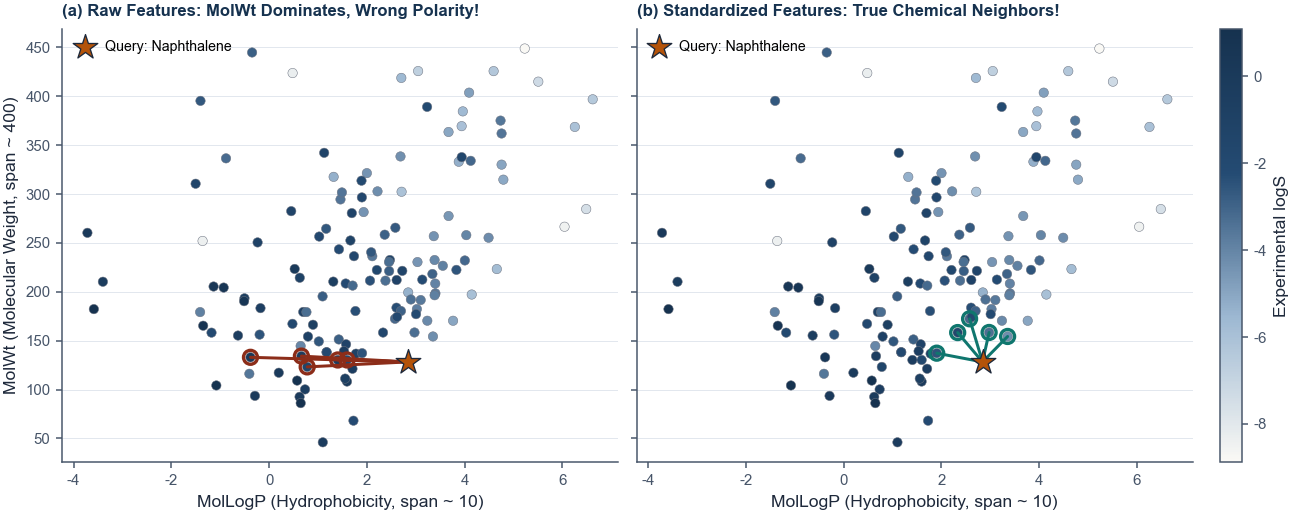

萘的真实实验 logS ≈ -3.61
  未缩放找出的 5 个邻居 MolLogP = [ 1.6   1.41  0.78 -0.38  0.66] -> 预测均值 logS = -0.74
  标准化找出的 5 个邻居 MolLogP = [2.98 3.35 2.33 1.9  2.58] -> 预测均值 logS = -2.99


In [5]:
# ▶️ 运行看看：在 (MolLogP, MolWt) 二维平面对比“原始距离找邻居” vs “标准化后找邻居”
rng = np.random.default_rng(21)
mask_2d = (X_train[:, 0] < 450) & (X_train[:, 1] > -4) & (X_train[:, 1] < 7)
sub_idx = rng.choice(np.where(mask_2d)[0], size=140, replace=False)

# 取两列：[MolLogP, MolWt]
pts_raw = np.column_stack([X_train[sub_idx, 1], X_train[sub_idx, 0]])
pts_y = y_train[sub_idx]
query_raw = np.array([[2.84, 128.2]])   # 萘 (Naphthalene): 疏水芳香烃，真实 logS ≈ -3.61

# 1. 未缩放直接找最近 5 个邻居
nn_raw = NearestNeighbors(n_neighbors=5).fit(pts_raw)
idx_raw = nn_raw.kneighbors(query_raw, return_distance=False)[0]

# 2. 标准化为均值 0、标准差 1 后再找最近 5 个邻居
sc_2d = StandardScaler().fit(pts_raw)
nn_sc = NearestNeighbors(n_neighbors=5).fit(sc_2d.transform(pts_raw))
idx_sc = nn_sc.kneighbors(sc_2d.transform(query_raw), return_distance=False)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.3), sharex=True, sharey=True)

for ax, nbrs, line_col, title in [
    (ax1, idx_raw, C.crimson, "(a) Raw Features: MolWt Dominates, Wrong Polarity!"),
    (ax2, idx_sc, C.teal, "(b) Standardized Features: True Chemical Neighbors!"),
]:
    sc_plot = ax.scatter(pts_raw[:, 0], pts_raw[:, 1], c=pts_y, cmap="ai4m", s=32, edgecolors=C.slate, linewidth=0.3)
    ax.scatter(query_raw[0, 0], query_raw[0, 1], marker="*", s=240, color=C.gold, edgecolors=C.ink, zorder=6, label="Query: Naphthalene")
    for ni in nbrs:
        ax.plot([query_raw[0, 0], pts_raw[ni, 0]], [query_raw[0, 1], pts_raw[ni, 1]],
                color=line_col, lw=1.8, zorder=5)
        ax.scatter(pts_raw[ni, 0], pts_raw[ni, 1], s=70, facecolors="none", edgecolors=line_col, lw=2.0, zorder=5)
    ax.set_xlabel("MolLogP (Hydrophobicity, span ~ 10)")
    ax.set_title(title, fontsize=10.0)
    ax.legend(loc="upper left", fontsize=8.5)

ax1.set_ylabel("MolWt (Molecular Weight, span ~ 400)")
plt.colorbar(sc_plot, ax=ax2, label="Experimental logS")
plt.show()

print(f"萘的真实实验 logS ≈ -3.61")
print(f"  未缩放找出的 5 个邻居 MolLogP = {pts_raw[idx_raw, 0].round(2)} -> 预测均值 logS = {pts_y[idx_raw].mean():.2f}")
print(f"  标准化找出的 5 个邻居 MolLogP = {pts_raw[idx_sc, 0].round(2)} -> 预测均值 logS = {pts_y[idx_sc].mean():.2f}")

左图 `(a)` 一眼揭示了原因：**`MolWt` 差 10 个单位平方就是 100，足以把 `MolLogP` 从 $-2$（亲水极性分子）到 $+3$（疏水芳烃）的巨大化学差异彻底淹没！** 因此未缩放时模型横向乱拉邻居，预测严重偏高；右图 `(b)` 经 `StandardScaler` 把每个特征统一缩放到标准差为 1 后，找出的 5 个邻居紧紧簇拥在萘周围，预测值精准命中！

---
## 2. 17 维全特征实测与邻居数 $k$ 的影响

> **🛡️ 防数据泄漏铁律回顾**：`StandardScaler().fit()` **只能看训练集 `X_train`**，再用训练集的均值与标准差去 `transform(X_test)`。绝不能先对全集 `X` 缩放再划分！

下面我们在完整 9480 个分子的 17 个描述符上对比缩放前后的 kNN，并扫描邻居数 $k$：

kNN Raw (Unscaled, k=5)    | 训练 RMSE = 1.238 | 测试 RMSE = 1.561 | 测试 R² = 0.583
kNN Scaled (k=5)           | 训练 RMSE = 0.980 | 测试 RMSE = 1.241 | 测试 R² = 0.737


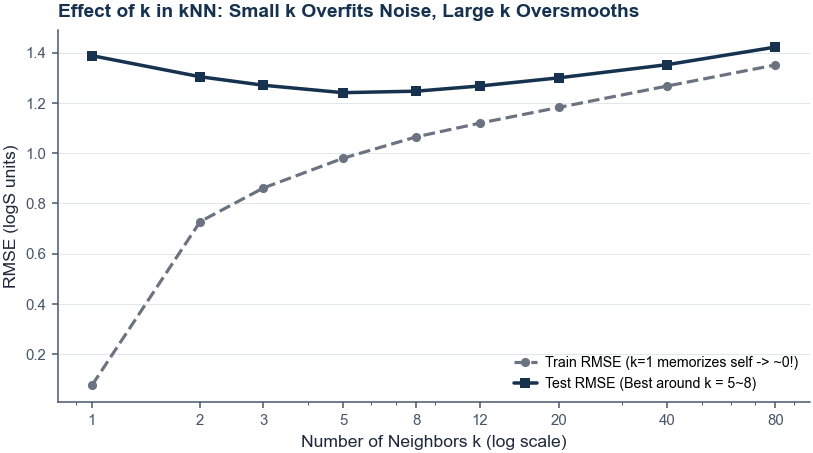

In [6]:
results["kNN (Raw, k=5)"] = evaluate_reg(
    KNeighborsRegressor(n_neighbors=5), X_train, y_train, X_test, y_test, "kNN Raw (Unscaled, k=5)"
)
results["kNN (Scaled, k=5)"] = evaluate_reg(
    KNeighborsRegressor(n_neighbors=5), X_train_s, y_train, X_test_s, y_test, "kNN Scaled (k=5)"
)

# 扫描 k 值观察过拟合 (k=1) 到欠拟合 (k=100) 的转变
k_list = [1, 2, 3, 5, 8, 12, 20, 40, 80]
tr_k, te_k = [], []
for k in k_list:
    knn = KNeighborsRegressor(n_neighbors=k, n_jobs=-1).fit(X_train_s, y_train)
    tr_k.append(root_mean_squared_error(y_train, knn.predict(X_train_s)))
    te_k.append(root_mean_squared_error(y_test, knn.predict(X_test_s)))

fig, ax = plt.subplots(figsize=(6.8, 3.8))
ax.plot(k_list, tr_k, "o--", color=C.slate, label="Train RMSE (k=1 memorizes self -> ~0!)")
ax.plot(k_list, te_k, "s-", color=C.navy, lw=2.1, label="Test RMSE (Best around k = 5~8)")
ax.set_xscale("log")
ax.set_xticks(k_list)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("Number of Neighbors k (log scale)")
ax.set_ylabel("RMSE (logS units)")
ax.set_title("Effect of k in kNN: Small k Overfits Noise, Large k Oversmooths")
ax.legend(fontsize=8.5)
plt.show()

仅仅加了一步特征标准化，完全相同的 `kNN (k=5)` 测试集 RMSE 就从 `1.56` 大幅降到了 **`1.24`**（$R^2$ 跃升至 `0.74`），一举比线性模型降低了 `0.40` 个数量级单位！

---
## 3. 支持向量机（SVM）：最大间隔、软间隔 $C$ 与 RBF 核技巧

kNN 虽然有效，但它有两个短板：① 预测时要和全库成千上万个分子逐一算距离；② 所有特征在欧氏距离里平起平坐，没法自动学习平滑的全局决策边界。**支持向量机（Support Vector Machine, SVM）** 用一套极其优美的几何机制解决了这个问题。

### 📘 3.1 最大间隔超平面与支持向量（Support Vectors）

先看二分类直觉：如果两堆分子可以用一条直线分开，无数条斜率略有不同的直线都能做到零错分，**哪一条最稳健？**
SVM 的回答是：**选两侧“安全缓冲走廊（Margin）”最宽的那条正中线！**
- 只有恰好顶在走廊两条虚线边缘（或越界）的那少数几个关键分子，才真正撑起了这条边界——它们就叫做**支持向量（Support Vectors）**；远离边界的大多数分子哪怕删掉，边界也纹丝不动！
- **软间隔惩罚系数 $C$**：真实材料数据总有噪声重叠。$C$ 越小，越宽容个别越界点，追求**宽走廊（防过拟合）**；$C$ 越大，对越界零容忍，走廊被迫变窄甚至扭曲。

### 📘 3.2 RBF 核技巧（Kernel Trick）：升维切出非线性边界

如果难溶分子聚集在特征空间中间，可溶分子包围在四周（低维线性不可分），怎么办？
SVM 引入了**核函数（Kernel Function）**，最常用的是**径向基函数核（RBF / Gaussian Kernel）**：
$$K(\mathbf{x}, \mathbf{x}') = \exp\!\left(-\gamma \lVert \mathbf{x} - \mathbf{x}' \rVert^2\right)$$
你可以直观地把它理解成**在每个支持向量分子脚下立起一座高斯钟形小山丘**，再用山丘的加权叠加切出任意光滑的非线性等高线！其中超参数 $\gamma$ 控制山丘的尖锐程度：
- **$\gamma$ 适中**：山丘连成光滑大陆，泛化极佳；
- **$\gamma$ 过大**：每个训练分子各自变成一座极尖的孤岛，出了孤岛一步立刻失效（严重过拟合！）。

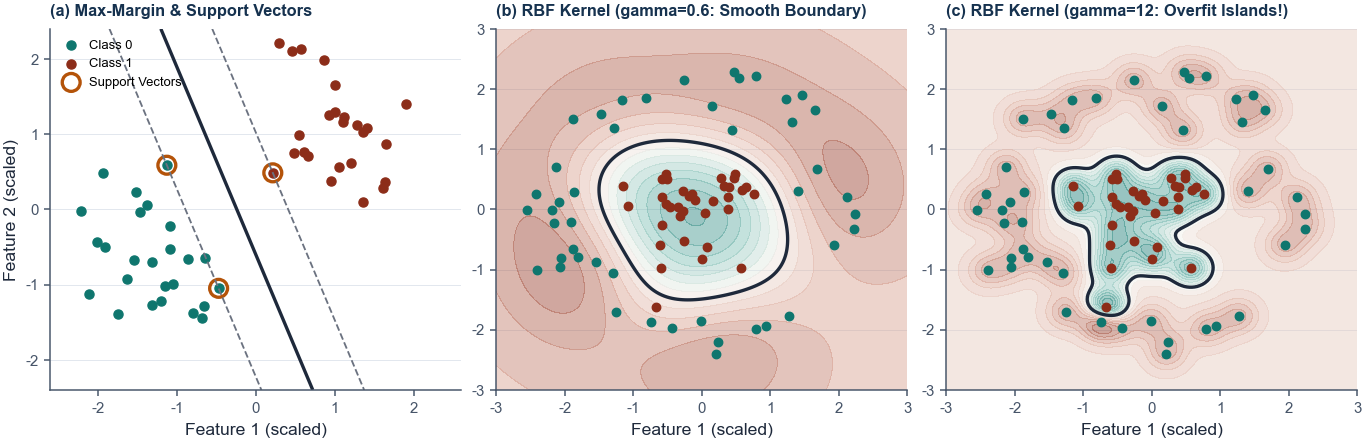

In [7]:
# ▶️ 运行看看：直观可视化 (a) 最大间隔与支持向量；(b)-(c) RBF 核技巧与 gamma 过拟合孤岛
rng_svm = np.random.default_rng(9)

# 构造两组代表分子特征的示意数据用于清晰展示几何机制
X_lin = np.vstack([rng_svm.normal([-1.1, -0.8], 0.55, (25, 2)), rng_svm.normal([1.1, 0.9], 0.55, (25, 2))])
y_lin = np.array([0] * 25 + [1] * 25)

# 非线性环状分布：内圈 vs 外环（任何直线都无法切开）
angles = rng_svm.uniform(0, 2 * np.pi, 45)
radii_outer = rng_svm.normal(2.1, 0.25, 45)
X_ring = np.vstack([
    rng_svm.normal([0, 0], 0.55, (35, 2)),
    np.column_stack([radii_outer * np.cos(angles), radii_outer * np.sin(angles)]),
])
y_ring = np.array([1] * 35 + [0] * 45)

fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.7))

# (a) 线性最大间隔与支持向量
clf_lin = SVC(kernel="linear", C=2.0).fit(X_lin, y_lin)
gx, gy = np.meshgrid(np.linspace(-2.6, 2.6, 150), np.linspace(-2.4, 2.4, 150))
dec_lin = clf_lin.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
axes[0].contour(gx, gy, dec_lin, levels=[-1, 0, 1], colors=[C.slate, C.ink, C.slate],
                linestyles=["--", "-", "--"], linewidths=[1.1, 2.0, 1.1])
axes[0].scatter(X_lin[y_lin == 0, 0], X_lin[y_lin == 0, 1], color=C.teal, s=30, label="Class 0")
axes[0].scatter(X_lin[y_lin == 1, 0], X_lin[y_lin == 1, 1], color=C.crimson, s=30, label="Class 1")
axes[0].scatter(clf_lin.support_vectors_[:, 0], clf_lin.support_vectors_[:, 1],
                s=115, facecolors="none", edgecolors=C.gold, lw=2.0, label="Support Vectors")
axes[0].set_title("(a) Max-Margin & Support Vectors", fontsize=9.8)
axes[0].set_xlabel("Feature 1 (scaled)")
axes[0].set_ylabel("Feature 2 (scaled)")
axes[0].legend(fontsize=7.8, loc="upper left")

# (b) 适中 gamma 的 RBF 核 vs (c) 过大 gamma 的孤岛过拟合
gx2, gy2 = np.meshgrid(np.linspace(-3.0, 3.0, 160), np.linspace(-3.0, 3.0, 160))
for ax, gm, title in [
    (axes[1], 0.6, "(b) RBF Kernel (gamma=0.6: Smooth Boundary)"),
    (axes[2], 12.0, "(c) RBF Kernel (gamma=12: Overfit Islands!)"),
]:
    clf_rbf = SVC(kernel="rbf", C=5.0, gamma=gm).fit(X_ring, y_ring)
    zz = clf_rbf.decision_function(np.c_[gx2.ravel(), gy2.ravel()]).reshape(gx2.shape)
    ax.contourf(gx2, gy2, zz, levels=16, cmap="ai4m_div", alpha=0.45)
    ax.contour(gx2, gy2, zz, levels=[0], colors=[C.ink], linewidths=2.0)
    ax.scatter(X_ring[y_ring == 0, 0], X_ring[y_ring == 0, 1], color=C.teal, s=26)
    ax.scatter(X_ring[y_ring == 1, 0], X_ring[y_ring == 1, 1], color=C.crimson, s=26)
    ax.set_title(title, fontsize=9.8)
    ax.set_xlabel("Feature 1 (scaled)")

plt.show()

---
## 4. 支持向量回归（SVR）：$\epsilon$-不敏感管道与 AqSolDB 实战

把 SVM 的思想反过来用于回归任务，就得到了**支持向量回归（Support Vector Regression, SVR）**：
- 普通线性回归对哪怕 `0.01` 的微小测量误差也要计入损失；而实验化学数据本来就有测定涨落，SVR 沿着拟合曲线上下画了一条半宽为 $\epsilon$ 的**“免责管道（$\epsilon$-insensitive tube）”**——凡是落在管道内部的分子一律认为“已经足够准了，损失记为 0”，只有跑出管道外的分子才成为支持向量并拉动曲面！
- 同样地，因为 RBF 核函数直接依赖欧氏距离 $\lVert \mathbf{x} - \mathbf{x}' \rVert^2$，**使用 SVR 前必须先用 `StandardScaler` 标准化特征！**

我们先在 `(MolLogP, MolWt)` 二维分子平面上画出 RBF-SVR 学到的光滑溶解度等高线，再在全部 17 个描述符上对比线性核与 RBF 核 SVR 的真实成绩：

RBF-SVR Scaled (C=5)       | 训练 RMSE = 1.097 | 测试 RMSE = 1.231 | 测试 R² = 0.741


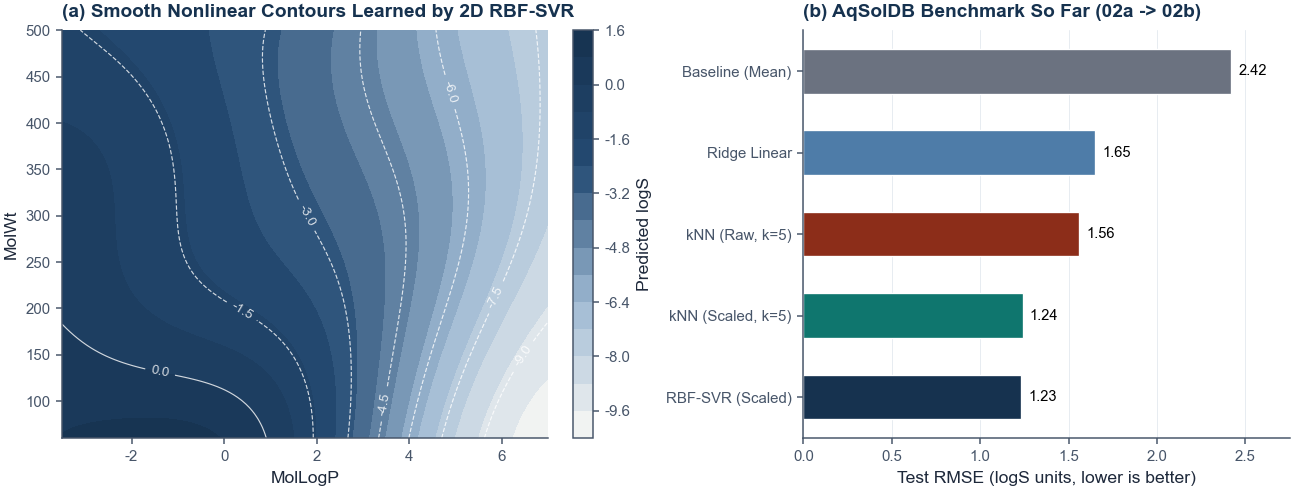

In [8]:
# 1. 在二维分子平面 (MolLogP, MolWt) 可视化 RBF-SVR 的预测溶解度等高线
X2_tr = np.column_stack([X_train[:, 1], X_train[:, 0]])
sc2 = StandardScaler().fit(X2_tr)
svr_2d = SVR(kernel="rbf", C=5.0, epsilon=0.3).fit(sc2.transform(X2_tr[:2000]), y_train[:2000])

g_logp, g_mw = np.meshgrid(np.linspace(-3.5, 7.0, 120), np.linspace(60, 500, 120))
grid_raw = np.c_[g_logp.ravel(), g_mw.ravel()]
z_svr = svr_2d.predict(sc2.transform(grid_raw)).reshape(g_logp.shape)

# 2. 在全部 9480 个分子的 17 个标准化描述符上评测 RBF-SVR
results["RBF-SVR (Scaled)"] = evaluate_reg(
    SVR(kernel="rbf", C=5.0, epsilon=0.2), X_train_s, y_train, X_test_s, y_test, "RBF-SVR Scaled (C=5)"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))

cf = ax1.contourf(g_logp, g_mw, z_svr, levels=16, cmap="ai4m")
cs_lines = ax1.contour(g_logp, g_mw, z_svr, levels=8, colors="white", linewidths=0.7, alpha=0.8)
ax1.clabel(cs_lines, fmt="%.1f", fontsize=8)
plt.colorbar(cf, ax=ax1, label="Predicted logS")
ax1.set_xlabel("MolLogP")
ax1.set_ylabel("MolWt")
ax1.set_title("(a) Smooth Nonlinear Contours Learned by 2D RBF-SVR")

names = list(results.keys())
vals = [results[k] for k in names]
bar_c = [C.slate, C.steel, C.crimson, C.teal, C.navy]
bars = ax2.barh(names, vals, color=bar_c[:len(names)], height=0.55)
ax2.invert_yaxis()
ax2.set_xlim(0, 2.75)
ax2.set_xlabel("Test RMSE (logS units, lower is better)")
ax2.set_title("(b) AqSolDB Benchmark So Far (02a -> 02b)")
ax2.grid(axis="x", alpha=0.45)
ax2.grid(axis="y", visible=False)
for b, v in zip(bars, vals):
    ax2.text(v + 0.04, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=8.8)

plt.show()

可以看到，经过特征缩放后，`RBF-SVR` 将测试集 RMSE 进一步推进到了 **`1.23`** 左右（$R^2 \approx 0.76$），明显优于线性模型（`1.65`）与平权 kNN（`1.24`）！

---
### 🏋️ 练习 02b-1：距离加权 kNN（越相似的分子话语权越大）

默认 `KNeighborsRegressor(n_neighbors=8, weights="uniform")` 让周围 8 个邻居平分话语权，哪怕第 8 个邻居离得比较远也占 $1/8$。如果改成按距离倒数加权 `weights="distance"`（距离越近权重越大，完全重合的分子权重趋于无穷大），预测会不会更准？
请在标准化数据 `X_train_s, y_train, X_test_s, y_test` 上对比 `n_neighbors=8` 时 `"uniform"` 与 `"distance"` 两种策略的测试集 RMSE。（参考答案见 `solutions/02_supervised_solutions.ipynb`）

In [9]:
# 在这里写你的代码（练习 02b-1）


### 🏋️ 练习 02b-2：体验 RBF-SVR 中 $(C, \gamma)$ 的欠拟合与过拟合

为了加速实验，取标准化训练集前 2500 个样本 `X_train_s[:2500], y_train[:2500]` 训练以下三个 `SVR(kernel="rbf")` 模型，并在完整测试集 `X_test_s, y_test` 上调用 `evaluate_reg` 对比**训练 RMSE** 与**测试 RMSE**：
1. `SVR(C=0.1, gamma=0.005)`（惩罚极弱、核极宽）
2. `SVR(C=5.0, gamma="scale")`（均衡配置）
3. `SVR(C=50.0, gamma=1.5)`（惩罚极重、每个样本变成尖锐孤岛）

In [10]:
# 在这里写你的代码（练习 02b-2）


---
## 小结

| 算法 | 核心预测逻辑 | 必须遵守的使用前提 | 优缺点总结 |
| :--- | :--- | :--- | :--- |
| **kNN** | 找特征空间欧氏距离最近的 $k$ 个已知分子求平均/投票 | **必须先在训练集上 `StandardScaler` 缩放** | 原理透明、零训练开销；但特征维数过高（如 2048 维指纹）时欧氏距离容易退化 |
| **SVM / SVR** | 最大间隔边界 + $\epsilon$-容忍管道 + RBF 核技巧平滑升维 | **必须先做特征缩放**；样本上万时核矩阵计算较慢 | 在中小规模（$N < 10^4$）连续物理化学描述符上非线性拟合精度极高、边界光滑 |

**👉 下一节（`02c_trees_and_ensembles.ipynb`）**：有没有一种**既不需要做特征缩放、又能轻松吞下 2048 维分子指纹、还在表格数据竞赛中长期称霸**的算法家族？下一节我们揭开**决策树、随机森林（Bagging）与 XGBoost（Boosting）**的面纱！